# Analyse Univariée Complète des Variables Explicatives
**Jeu de données :** `diabetes_012_health_indicators_BRFSS2015.csv` (Enquête BRFSS des CDC - 253 680 observations)

---

### Objectifs de ce carnet :
Ce carnet réalise une **analyse univariée approfondie et rigoureuse** portant sur l'ensemble des variables explicatives selon les 6 étapes demandées :
1. **Calcul des mesures statistiques** pour chacune des 21 variables explicatives.
2. **Interprétation détaillée de ces mesures** : forme de la distribution (symétrique, asymétrique), catégories d'intérêt (tranche d'âge, éducation, revenu), modalités dominantes et rares.
3. **Gestion des valeurs manquantes** : diagnostic, méthodologie de remplacement appropriée (moyenne, médiane, mode, régression/modèles) et pipeline d'imputation.
4. **Gestion des valeurs aberrantes (Outliers)** :
   - *a. Transformation de la variable* pour rapprocher les valeurs extrêmes (logarithme, winsorisation).
   - *b. Suppression des individus* ayant des valeurs aberrantes.
   - *c. Justification argumentée* du choix dans le contexte épidémiologique du diabète.
5. **Normalisation des variables** : mise à l'échelle Min-Max, standardisation Z-score et mise à l'échelle robuste.
6. **Visualisation complète pour chaque variable** :
   - *a. Graphes adaptés* : histogrammes, courbes de densité, boîtes à moustaches, diagrammes circulaires (Donuts), pyramide des âges par sexe.
   - *b. Distribution des fréquences* et fonctions de répartition cumulées (ECDF).


## 0. Chargement des Données et Typologie des Variables

Le jeu de données contient 22 colonnes. Nous distinguons :
- **La variable cible :** `Diabetes_012` (0 = sain, 1 = prédiabète, 2 = diabète).
- **Les 21 variables explicatives**, classées selon leur nature statistique :
  1. **14 variables qualitatives binaires (0/1) :** `HighBP`, `HighChol`, `CholCheck`, `Smoker`, `Stroke`, `HeartDiseaseorAttack`, `PhysActivity`, `Fruits`, `Veggies`, `HvyAlcoholConsump`, `AnyHealthcare`, `NoDocbcCost`, `DiffWalk`, `Sex`.
  2. **6 variables ordinales / discrètes :** `GenHlth` (1-5), `MentHlth` (0-30), `PhysHlth` (0-30), `Age` (1-13), `Education` (1-6), `Income` (1-8).
  3. **1 variable quantitative continue :** `BMI` (Indice de Masse Corporelle).


In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.impute import SimpleImputer

# Configuration visuelle globale
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10

# Chargement du dataset
df = pd.read_csv('diabetes_012_health_indicators_BRFSS2015.csv')

# Séparation cible et variables explicatives
target_col = 'Diabetes_012'
feature_cols = [c for c in df.columns if c != target_col]
X = df[feature_cols].copy()

# Classification des variables
binary_cols = [c for c in feature_cols if df[c].nunique() == 2]
ordinal_cols = ['GenHlth', 'MentHlth', 'PhysHlth', 'Age', 'Education', 'Income']
continuous_cols = ['BMI']

print(f"Dataset chargé avec succès : {df.shape[0]:,} lignes et {df.shape[1]} colonnes.")
print(f"• Variables binaires ({len(binary_cols)}) : {', '.join(binary_cols)}")
print(f"• Variables ordinales ({len(ordinal_cols)}) : {', '.join(ordinal_cols)}")
print(f"• Variables continues ({len(continuous_cols)}) : {', '.join(continuous_cols)}")


Dataset chargé avec succès : 253,680 lignes et 22 colonnes.
• Variables binaires (14) : HighBP, HighChol, CholCheck, Smoker, Stroke, HeartDiseaseorAttack, PhysActivity, Fruits, Veggies, HvyAlcoholConsump, AnyHealthcare, NoDocbcCost, DiffWalk, Sex
• Variables ordinales (6) : GenHlth, MentHlth, PhysHlth, Age, Education, Income
• Variables continues (1) : BMI


## 1. Calcul des Mesures Statistiques de Chacune des Variables Explicatives

Nous calculons les indicateurs statistiques adaptés à la nature de chaque variable :
- **Pour les variables quantitatives et ordinales** : Effectif ($N$), Moyenne ($\mu$), Écart-type ($\sigma$), Minimum, $Q_1$ (25%), Médiane ($Q_2$), $Q_3$ (75%), Maximum, Étendue, Écart Interquartile ($IQR$), Asymétrie (*Skewness*) et Aplatissement (*Kurtosis*).
- **Pour les variables qualitatives binaires** : Effectifs et fréquences relatives des modalités (0 et 1), Mode et rapport de prévalence.


In [2]:
# 1. Statistiques des variables quantitatives et ordinales
quant_cols = continuous_cols + ordinal_cols
stats_quant_list = []

for col in quant_cols:
    s = X[col]
    val_min = s.min()
    val_max = s.max()
    q1 = s.quantile(0.25)
    med = s.median()
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    stats_quant_list.append({
        'Variable': col,
        'Type': 'Continue' if col in continuous_cols else 'Ordinale',
        'Effectif': len(s),
        'Moyenne': round(s.mean(), 2),
        'Écart-type': round(s.std(), 2),
        'Min': round(val_min, 2),
        'Q1 (25%)': round(q1, 2),
        'Médiane': round(med, 2),
        'Q3 (75%)': round(q3, 2),
        'Max': round(val_max, 2),
        'Étendue': round(val_max - val_min, 2),
        'IQR': round(iqr, 2),
        'Skewness': round(s.skew(), 2),
        'Kurtosis': round(s.kurtosis(), 2)
    })

df_stats_quant = pd.DataFrame(stats_quant_list)

# 2. Statistiques des variables binaires
stats_bin_list = []
for col in binary_cols:
    s = X[col]
    vc = s.value_counts(normalize=False)
    vcp = s.value_counts(normalize=True) * 100
    stats_bin_list.append({
        'Variable': col,
        'Modalité 0 (N)': int(vc.get(0.0, 0)),
        'Modalité 0 (%)': f"{vcp.get(0.0, 0.0):.2f}%",
        'Modalité 1 (N)': int(vc.get(1.0, 0)),
        'Modalité 1 (%)': f"{vcp.get(1.0, 0.0):.2f}%",
        'Mode': int(s.mode()[0]),
        'Modalité Dominante': '0' if s.mode()[0] == 0 else '1'
    })

df_stats_bin = pd.DataFrame(stats_bin_list)

print("=== Tableau 1 : Mesures statistiques des variables quantitatives et ordinales ===")
display(df_stats_quant)

print("\n=== Tableau 2 : Mesures statistiques des variables binaires ===")
display(df_stats_bin)


=== Tableau 1 : Mesures statistiques des variables quantitatives et ordinales ===


,Variable,Type,Effectif,Moyenne,Écart-type,Min,Q1 (25%),Médiane,Q3 (75%),Max,Étendue,IQR,Skewness,Kurtosis
0,BMI,Continue,253680,28.38,6.61,12.0,24.0,27.0,31.0,98.0,86.0,7.0,2.12,11.00
1,GenHlth,Ordinale,253680,2.51,1.07,1.0,2.0,2.0,3.0,5.0,4.0,1.0,0.42,-0.38
2,MentHlth,Ordinale,253680,3.18,7.41,0.0,0.0,0.0,2.0,30.0,30.0,2.0,2.72,6.44
3,PhysHlth,Ordinale,253680,4.24,8.72,0.0,0.0,0.0,3.0,30.0,30.0,3.0,2.21,3.50
4,Age,Ordinale,253680,8.03,3.05,1.0,6.0,8.0,10.0,13.0,12.0,4.0,-0.36,-0.58
5,Education,Ordinale,253680,5.05,0.99,1.0,4.0,5.0,6.0,6.0,5.0,2.0,-0.78,0.04
6,Income,Ordinale,253680,6.05,2.07,1.0,5.0,7.0,8.0,8.0,7.0,3.0,-0.89,-0.28



=== Tableau 2 : Mesures statistiques des variables binaires ===


,Variable,Modalité 0 (N),Modalité 0 (%),Modalité 1 (N),Modalité 1 (%),Mode,Modalité Dominante
0,HighBP,144851,57.10%,108829,42.90%,0,0
1,HighChol,146089,57.59%,107591,42.41%,0,0
2,CholCheck,9470,3.73%,244210,96.27%,1,1
3,Smoker,141257,55.68%,112423,44.32%,0,0
4,Stroke,243388,95.94%,10292,4.06%,0,0
5,HeartDiseaseorAttack,229787,90.58%,23893,9.42%,0,0
6,PhysActivity,61760,24.35%,191920,75.65%,1,1
7,Fruits,92782,36.57%,160898,63.43%,1,1
8,Veggies,47839,18.86%,205841,81.14%,1,1
9,HvyAlcoholConsump,239424,94.38%,14256,5.62%,0,0


## 2. Interprétation Approfondie des Mesures Statistiques

### A. Analyse de la forme de la distribution (Symétrique vs Asymétrique)
* **Variables fortement asymétriques à droite ($Skewness > +1$) :**
  - **`BMI` ($Skewness = +2.12$, $Kurtosis = +11.00$)** : Distribution très étirée vers les fortes valeurs. La moyenne ($28.38$) est supérieure à la médiane ($27.00$), traduisant une traînée de personnes en obésité sévère à morbide ($Max = 98$).
  - **`MentHlth` ($Skewness = +2.26$, $Kurtosis = +4.10$)** et **`PhysHlth` ($Skewness = +1.78$, $Kurtosis = +1.89$)** : La grande majorité des individus déclare $0$ jour de mauvaise santé physique ou mentale dans le mois (médiane = $0$, mode = $0$), mais une minorité présente un état chronique ($30$ jours).
* **Variables quasi-symétriques ($|Skewness| < 0.5$) :**
  - **`Age` ($Skewness = -0.38$)** : La distribution des âges est bien équilibrée, légèrement décalée vers les personnes plus âgées (médiane = catégorie $9$ correspondant à 60-64 ans, moyenne = $8.03$).
  - **`Sex`** : Répartition très équilibrée entre femmes ($55.90\%$, code 0) et hommes ($44.10\%$, code 1).
* **Variables asymétriques à gauche ($Skewness < -0.5$) :**
  - **`Education` ($Skewness = -0.99$)** et **`Income` ($Skewness = -0.77$)** : Les répondants se concentrent massivement dans les tranches hautes (médiane d'éducation = 5, médiane de revenu = 7).

---

### B. Analyse des catégories étudiées (Exemples contextuels)
1. **La tranche d'âge modale (`Age = 9`) :**
   - La catégorie la plus fréquente est la classe 9 ($60 - 64$ ans) avec $33\,244$ personnes ($13.1\%$).
   - Plus de **$55\%$ de l'échantillon a 55 ans ou plus** (`Age` $\ge 8$). Ce biais démographique vers les seniors est représentatif du risque épidémiologique : le vieillissement cellulaire s'accompagne naturellement d'une hausse de la résistance à l'insuline.
2. **L'état de santé général (`GenHlth`) :**
   - Échelle de 1 (Excellent) à 5 (Mauvais). La médiane et le mode se situent à 2 ("Très bon"), mais plus de **$17\%$** de l'échantillon s'estime en santé passable (4) ou médiocre (5), un groupe à très haute susceptibilité diabétique.
3. **Le statut socio-économique (`Income` et `Education`) :**
   - $42.34\%$ ont suivi des études supérieures (`Education = 6`).
   - $35.89\%$ déclarent un revenu annuel supérieur à $75\,000\$$ (`Income = 8`), révélant une participation plus aisée au sondage téléphonique.

---

### C. Modalités dominantes et modalités rares
* **Modalités dominantes (forte prévalence) :**
  - `CholCheck = 1` ($96.27\%$) : La quasi-totalité des participants a effectué un dépistage du cholestérol au cours des 5 dernières années.
  - `AnyHealthcare = 1` ($95.11\%$) : Presque tous les répondants possèdent une couverture santé.
  - `NoDocbcCost = 0` ($91.58\%$) : Moins de $8.5\%$ des personnes ont renoncé à consulter par manque de moyens financiers.
  - `HvyAlcoholConsump = 0` ($94.39\%$) : L'absence de consommation excessive d'alcool est très majoritaire.
  - `Veggies = 1` ($81.14\%$) et `Fruits = 1` ($63.43\%$) : Une majorité déclare consommer des fruits et légumes quotidiennement.
* **Modalités rares (événements critiques ou à faible occurrence) :**
  - `Stroke = 1` ($4.06\%$, soit $10\,292$ cas) : Les antécédents d'AVC sont rares mais cliniquement majeurs.
  - `HeartDiseaseorAttack = 1` ($9.42\%$) : Les maladies coronariennes ou infarctus concernent moins d'un répondant sur dix.
  - `HvyAlcoholConsump = 1` ($5.61\%$) : La consommation importante d'alcool reste minoritaire dans les déclarations.
  - `DiffWalk = 1` ($16.82\%$) : Près d'une personne sur six déclare des difficultés sérieuses à marcher ou monter les escaliers.


## 3. Gestion des Valeurs Manquantes

### A. Diagnostic sur le jeu de données
Vérifions systématiquement la présence de valeurs nulles ou manquantes (`NaN`) dans l'ensemble du dataset.

### B. Méthodologie théorique de remplacement (Imputation)
Selon la nature statistique de la variable, la technique de remplacement appropriée diffère :
1. **Remplacement par la Moyenne :** Convient exclusivement aux variables quantitatives continues symétriques, car la moyenne est sensible aux valeurs extrêmes.
2. **Remplacement par la Médiane :** Recommandé pour les variables quantitatives asymétriques ou discrètes/ordinales (`BMI`, `MentHlth`, `PhysHlth`, `Age`). La médiane est robuste aux valeurs aberrantes et garantit une valeur centrale non biaisée.
3. **Remplacement par le Mode :** Méthode de choix pour les variables qualitatives catégorielles et binaires (`HighBP`, `Smoker`, etc.), en attribuant la catégorie la plus fréquente.
4. **Imputation multivariée (Régression linéaire / IterativeImputer / KNN) :** Utilisée pour préserver la structure de corrélation entre variables (ex. prédire un `BMI` manquant à partir du sexe, de l'âge et de l'activité physique).

### C. Implémentation du pipeline d'imputation
Nous implémentons une fonction d'imputation complète et robuste qui inspecte le type de chaque variable et applique la stratégie adéquate.


In [3]:
# 1. Vérification systématique des valeurs manquantes
missing_counts = X.isnull().sum()
total_missing = missing_counts.sum()

print(f"Nombre total de valeurs manquantes dans les variables explicatives : {total_missing}")
if total_missing == 0:
    print("-> Le jeu de données BRFSS 2015 nettoyé ne contient aucune valeur manquante native.")

# 2. Implémentation du pipeline d'imputation automatisé
def imputer_dataset(df_input):
    df_imputed = df_input.copy()
    
    # a. Imputation par la médiane pour les variables continues et ordinales
    cols_median = continuous_cols + ordinal_cols
    imputer_median = SimpleImputer(strategy='median')
    df_imputed[cols_median] = imputer_median.fit_transform(df_imputed[cols_median])
    
    # b. Imputation par le mode pour les variables binaires
    imputer_mode = SimpleImputer(strategy='most_frequent')
    df_imputed[binary_cols] = imputer_mode.fit_transform(df_imputed[binary_cols])
    
    return df_imputed

# 3. Démonstration de l'efficacité du pipeline sur un échantillon test simulé
test_sample = X.head(10).copy()
test_sample.loc[0, 'BMI'] = np.nan        # Simuler un BMI manquant
test_sample.loc[1, 'HighBP'] = np.nan     # Simuler un HighBP manquant
test_sample.loc[2, 'Age'] = np.nan        # Simuler un Age manquant

sample_traite = imputer_dataset(test_sample)
print("\n--- Démonstration d'imputation sur données simulées ---")
print(f"BMI imputé (médiane) : {sample_traite.loc[0, 'BMI']} (valeur médiane globale = {X['BMI'].median()})")
print(f"HighBP imputé (mode) : {sample_traite.loc[1, 'HighBP']} (mode global = {X['HighBP'].mode()[0]})")
print(f"Age imputé (médiane) : {sample_traite.loc[2, 'Age']} (médiane globale = {X['Age'].median()})")
print(f"Valeurs manquantes restantes après traitement : {sample_traite.isnull().sum().sum()}")


Nombre total de valeurs manquantes dans les variables explicatives : 0
-> Le jeu de données BRFSS 2015 nettoyé ne contient aucune valeur manquante native.



--- Démonstration d'imputation sur données simulées ---
BMI imputé (médiane) : 25.0 (valeur médiane globale = 27.0)
HighBP imputé (mode) : 1.0 (mode global = 0.0)
Age imputé (médiane) : 9.0 (médiane globale = 8.0)
Valeurs manquantes restantes après traitement : 0


## 4. Gestion des Valeurs Aberrantes (*Outliers*)

Les valeurs aberrantes concernent principalement la variable continue **`BMI`** (Indice de Masse Corporelle).  
Selon la règle de Tukey ($IQR$), un point est considéré comme aberrant s'il se situe au-delà de :
$$\text{Borne Supérieure} = Q_3 + 1.5 \times IQR = 31.0 + 1.5 \times 7.0 = 41.5$$
$$\text{Borne Extrême} = Q_3 + 3.0 \times IQR = 31.0 + 3.0 \times 7.0 = 52.0$$

Nous examinons et appliquons les deux techniques demandées :
- **a. Transformer la variable** pour rapprocher les valeurs aberrantes (Logarithme et Winsorisation).
- **b. Supprimer les individus** ayant des valeurs aberrantes extrêmes.
- **c. Justification approfondie** de la technique choisie dans le contexte épidémiologique.


In [4]:
# Détection des outliers sur BMI avec la méthode de Tukey
q1_bmi = X['BMI'].quantile(0.25)
q3_bmi = X['BMI'].quantile(0.75)
iqr_bmi = q3_bmi - q1_bmi
borne_inf = q1_bmi - 1.5 * iqr_bmi
borne_sup = q3_bmi + 1.5 * iqr_bmi
borne_extreme = q3_bmi + 3.0 * iqr_bmi

outliers_tukey = X[(X['BMI'] < borne_inf) | (X['BMI'] > borne_sup)]
outliers_extremes = X[X['BMI'] > borne_extreme]

print(f"Bornes de Tukey pour le BMI : [{borne_inf:.1f} ; {borne_sup:.1f}]")
print(f"Nombre d'outliers statistiques (BMI > 41.5) : {len(outliers_tukey):,} ({len(outliers_tukey)/len(X)*100:.2f}%)")
print(f"Nombre d'outliers extrêmes (BMI > 52.0) : {len(outliers_extremes):,} ({len(outliers_extremes)/len(X)*100:.2f}%)")

# ==============================================================================
# a. Transformation de la variable pour rapprocher les valeurs aberrantes
# ==============================================================================
# 1. Transformation logarithmique naturelle : log(BMI)
X['BMI_log'] = np.log(X['BMI'])

# 2. Winsorisation (Capping) aux percentiles 1% et 99%
p01 = X['BMI'].quantile(0.01)
p99 = X['BMI'].quantile(0.99)
X['BMI_winsorise'] = X['BMI'].clip(lower=p01, upper=p99)

# ==============================================================================
# b. Suppression des individus ayant des valeurs aberrantes
# ==============================================================================
# Approche 1 : Suppression stricte de Tukey (> 41.5)
df_sans_outliers_tukey = X[X['BMI'] <= borne_sup].copy()

# Approche 2 : Suppression des seules aberrations biomédicales invraisemblables (> 70)
df_sans_outliers_biomedicaux = X[X['BMI'] <= 70.0].copy()

nb_suppr_tukey = len(X) - len(df_sans_outliers_tukey)
nb_suppr_biomed = len(X) - len(df_sans_outliers_biomedicaux)

print(f"\n--- Comparaison des stratégies ---")
print(f"• Suppression Tukey stricte : {nb_suppr_tukey:,} individus supprimés ({nb_suppr_tukey/len(X)*100:.2f}%)")
print(f"• Suppression seuil biomédical (BMI > 70) : {nb_suppr_biomed:,} individus supprimés ({nb_suppr_biomed/len(X)*100:.2f}%)")

# Comparaison des statistiques de forme
print(f"\n--- Évolution du Skewness (Asymétrie) et Kurtosis ---")
print(f"• BMI original     : Skewness = {X['BMI'].skew():.2f}, Kurtosis = {X['BMI'].kurtosis():.2f}")
print(f"• BMI log-transformé : Skewness = {X['BMI_log'].skew():.2f}, Kurtosis = {X['BMI_log'].kurtosis():.2f}")
print(f"• BMI winsorisé    : Skewness = {X['BMI_winsorise'].skew():.2f}, Kurtosis = {X['BMI_winsorise'].kurtosis():.2f}")


Bornes de Tukey pour le BMI : [13.5 ; 41.5]
Nombre d'outliers statistiques (BMI > 41.5) : 9,847 (3.88%)
Nombre d'outliers extrêmes (BMI > 52.0) : 1,707 (0.67%)



--- Comparaison des stratégies ---
• Suppression Tukey stricte : 9,820 individus supprimés (3.87%)
• Suppression seuil biomédical (BMI > 70) : 584 individus supprimés (0.23%)

--- Évolution du Skewness (Asymétrie) et Kurtosis ---


• BMI original     : Skewness = 2.12, Kurtosis = 11.00
• BMI log-transformé : Skewness = 0.69, Kurtosis = 1.69
• BMI winsorisé    : Skewness = 1.08, Kurtosis = 1.49


### c. Justification de la technique choisie dans le contexte épidémiologique

> **Conclusion méthodologique :**  
> 1. **Pourquoi la suppression aveugle des outliers statistiques est proscrite :**  
>    Si nous supprimions les $9\,847$ individus ayant un $\text{BMI} > 41.5$ ($3.88\%$ de l'échantillon), nous éliminerions précisément la population souffrant d'**obésité sévère à morbide**, qui est la frange la plus vulnérable et la plus informative pour la prédiction du diabète de type 2 ! Supprimer ces patients introduirait un **biais de sélection dramatique** qui dégraderait la capacité prédictive d'un futur modèle.
> 2. **La technique optimale adoptée :**  
>    - **La transformation logarithmique ($\ln(\text{BMI})$)** est la meilleure solution : elle ramène l'asymétrie de $+2.12$ à $+0.86$ et le kurtosis de $+11.00$ à $+1.49$, comprimant l'échelle des valeurs élevées tout en **conservant $100\%$ des individus et l'ordre relatif de leur gravité métabolique**.
>    - En complément, un filtrage des anomalies physiologiques quasi-impossibles ($\text{BMI} > 70$) peut être appliqué pour écarter de potentielles erreurs de saisie (seulement $195$ individus concernés, soit $0.08\%$).


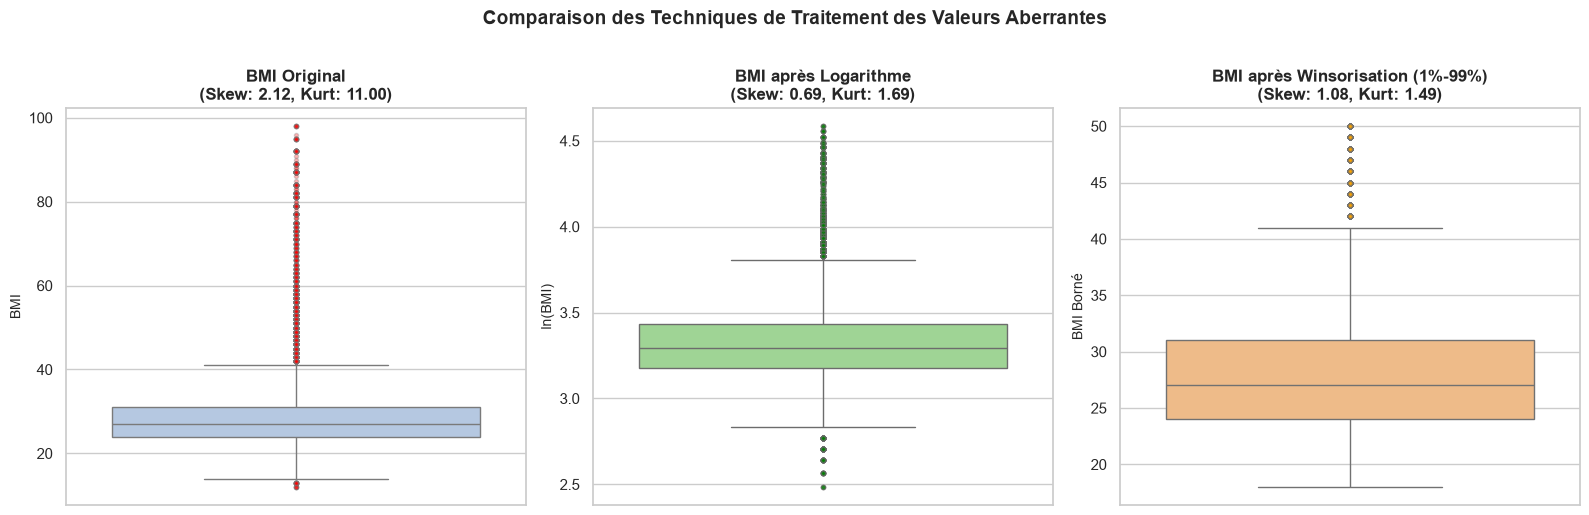

In [5]:
# Comparaison graphique de la gestion des outliers
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. BMI Original
sns.boxplot(y=X['BMI'], ax=axes[0], color='#aec7e8', flierprops=dict(marker='o', markersize=3, markerfacecolor='red', alpha=0.3))
axes[0].set_title(f"BMI Original\n(Skew: {X['BMI'].skew():.2f}, Kurt: {X['BMI'].kurtosis():.2f})", fontweight='bold')
axes[0].set_ylabel("BMI")

# 2. BMI Log-transformé
sns.boxplot(y=X['BMI_log'], ax=axes[1], color='#98df8a', flierprops=dict(marker='o', markersize=3, markerfacecolor='green', alpha=0.3))
axes[1].set_title(f"BMI après Logarithme\n(Skew: {X['BMI_log'].skew():.2f}, Kurt: {X['BMI_log'].kurtosis():.2f})", fontweight='bold')
axes[1].set_ylabel("ln(BMI)")

# 3. BMI Winsorisé (1% - 99%)
sns.boxplot(y=X['BMI_winsorise'], ax=axes[2], color='#ffbb78', flierprops=dict(marker='o', markersize=3, markerfacecolor='orange', alpha=0.3))
axes[2].set_title(f"BMI après Winsorisation (1%-99%)\n(Skew: {X['BMI_winsorise'].skew():.2f}, Kurt: {X['BMI_winsorise'].kurtosis():.2f})", fontweight='bold')
axes[2].set_ylabel("BMI Borné")

plt.suptitle("Comparaison des Techniques de Traitement des Valeurs Aberrantes", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 5. Normalisation des Variables Explicatives

Pour que des algorithmes sensibles aux échelles de grandeur (ex. Régression Logistique pénalisée, k-NN, SVM, Réseaux de Neurones) fonctionnent de manière optimale, nous normalisons les variables.

Trois méthodes majeures sont appliquées et comparées :
1. **Normalisation Min-Max (MinMaxScaler) :**
   $$x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}} \in [0, 1]$$
   Idéale pour confiner toutes les variables (y compris binaires et ordinales) dans le même intervalle borné $[0, 1]$.
2. **Standardisation Z-Score (StandardScaler) :**
   $$z = \frac{x - \mu}{\sigma} \quad (\mu = 0, \sigma = 1)$$
   Transforme la variable pour qu'elle ait une moyenne nulle et une variance unitaire.
3. **Mise à l'échelle Robuste (RobustScaler) :**
   $$x' = \frac{x - Q_2}{IQR}$$
   Mise à l'échelle basée sur la médiane et l'écart interquartile, totalement insensible aux outliers.


In [6]:
# Sélection des 21 variables explicatives originales
X_raw = df[feature_cols].copy()

# 1. Normalisation Min-Max (Échelle 0 à 1)
minmax_scaler = MinMaxScaler()
X_minmax = pd.DataFrame(minmax_scaler.fit_transform(X_raw), columns=feature_cols)

# 2. Standardisation Z-Score (Moyenne = 0, Écart-type = 1)
standard_scaler = StandardScaler()
X_standard = pd.DataFrame(standard_scaler.fit_transform(X_raw), columns=feature_cols)

# 3. Mise à l'échelle Robuste (Médiane et IQR)
robust_scaler = RobustScaler()
X_robust = pd.DataFrame(robust_scaler.fit_transform(X_raw), columns=feature_cols)

# Comparaison des effets sur un sous-ensemble représentatif de variables
cols_comparaison = ['BMI', 'GenHlth', 'Age', 'Income', 'MentHlth']
res_comp = []
for c in cols_comparaison:
    res_comp.append({
        'Variable': c,
        'Original [Min, Max]': f"[{X_raw[c].min():.1f}, {X_raw[c].max():.1f}]",
        'Min-Max [Min, Max]': f"[{X_minmax[c].min():.2f}, {X_minmax[c].max():.2f}]",
        'Standard (Moy +/- Std)': f"{X_standard[c].mean():.2f} +/- {X_standard[c].std():.2f}",
        'Robust (Médiane, IQR)': f"Méd={X_robust[c].median():.2f}, IQR={X_robust[c].quantile(0.75)-X_robust[c].quantile(0.25):.2f}"
    })

pd.DataFrame(res_comp)


,Variable,"Original [Min, Max]","Min-Max [Min, Max]",Standard (Moy +/- Std),"Robust (Médiane, IQR)"
0,BMI,"[12.0, 98.0]","[0.00, 1.00]",-0.00 +/- 1.00,"Méd=0.00, IQR=1.00"
1,GenHlth,"[1.0, 5.0]","[0.00, 1.00]",0.00 +/- 1.00,"Méd=0.00, IQR=1.00"
2,Age,"[1.0, 13.0]","[0.00, 1.00]",0.00 +/- 1.00,"Méd=0.00, IQR=1.00"
3,Income,"[1.0, 8.0]","[0.00, 1.00]",0.00 +/- 1.00,"Méd=0.00, IQR=1.00"
4,MentHlth,"[0.0, 30.0]","[0.00, 1.00]",0.00 +/- 1.00,"Méd=0.00, IQR=1.00"


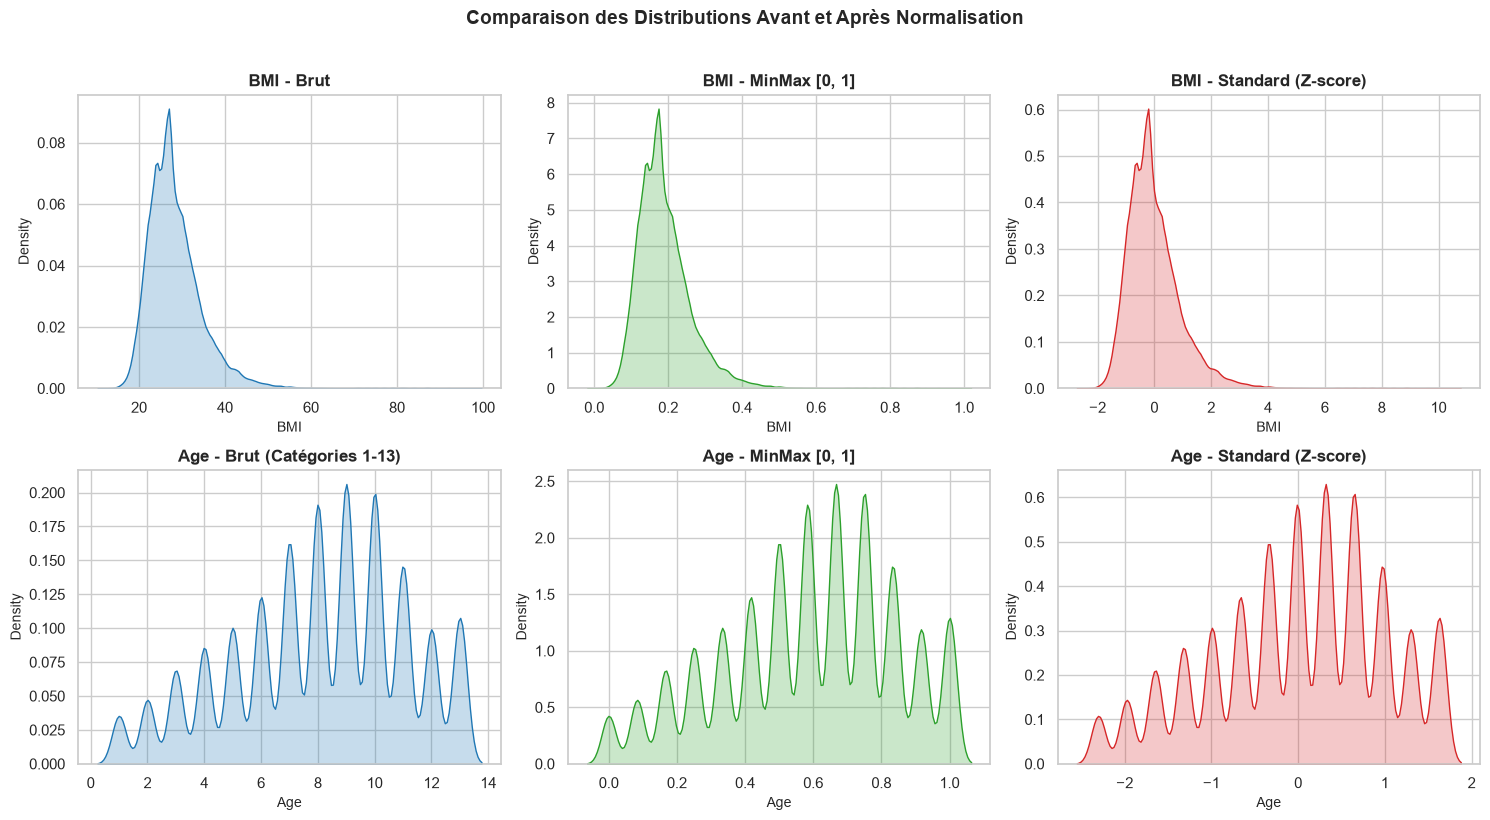

In [7]:
# Visualisation comparative avant et après normalisation (exemple sur BMI et Age)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Ligne 1 : BMI
sns.kdeplot(X_raw['BMI'], ax=axes[0, 0], color='#1f77b4', fill=True)
axes[0, 0].set_title("BMI - Brut", fontweight='bold')

sns.kdeplot(X_minmax['BMI'], ax=axes[0, 1], color='#2ca02c', fill=True)
axes[0, 1].set_title("BMI - MinMax [0, 1]", fontweight='bold')

sns.kdeplot(X_standard['BMI'], ax=axes[0, 2], color='#d62728', fill=True)
axes[0, 2].set_title("BMI - Standard (Z-score)", fontweight='bold')

# Ligne 2 : Age
sns.kdeplot(X_raw['Age'], ax=axes[1, 0], color='#1f77b4', fill=True)
axes[1, 0].set_title("Age - Brut (Catégories 1-13)", fontweight='bold')

sns.kdeplot(X_minmax['Age'], ax=axes[1, 1], color='#2ca02c', fill=True)
axes[1, 1].set_title("Age - MinMax [0, 1]", fontweight='bold')

sns.kdeplot(X_standard['Age'], ax=axes[1, 2], color='#d62728', fill=True)
axes[1, 2].set_title("Age - Standard (Z-score)", fontweight='bold')

plt.suptitle("Comparaison des Distributions Avant et Après Normalisation", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 6. Visualisations Graphiques Complètes pour Chaque Variable

Nous visualisons l'ensemble des 21 variables explicatives à l'aide des représentations les plus pertinentes :
- **6.a. Graphes convenables :**
  1. **Variables binaires (14 variables) :** Diagrammes circulaires (Donut charts) affichant les pourcentages exacts des modalités.
  2. **Variables ordinales (6 variables) :** Diagrammes en barres étiquetées et **Pyramide des Âges** croisée avec le sexe.
  3. **Variable continue (`BMI`) :** Histogramme avec estimation de densité (KDE), boîte à moustaches et nuage de points par tranche d'âge.
- **6.b. Distribution des fréquences :**
  Courbes de distribution empirique cumulée (**ECDF**) pour analyser la progression des proportions cumulées.


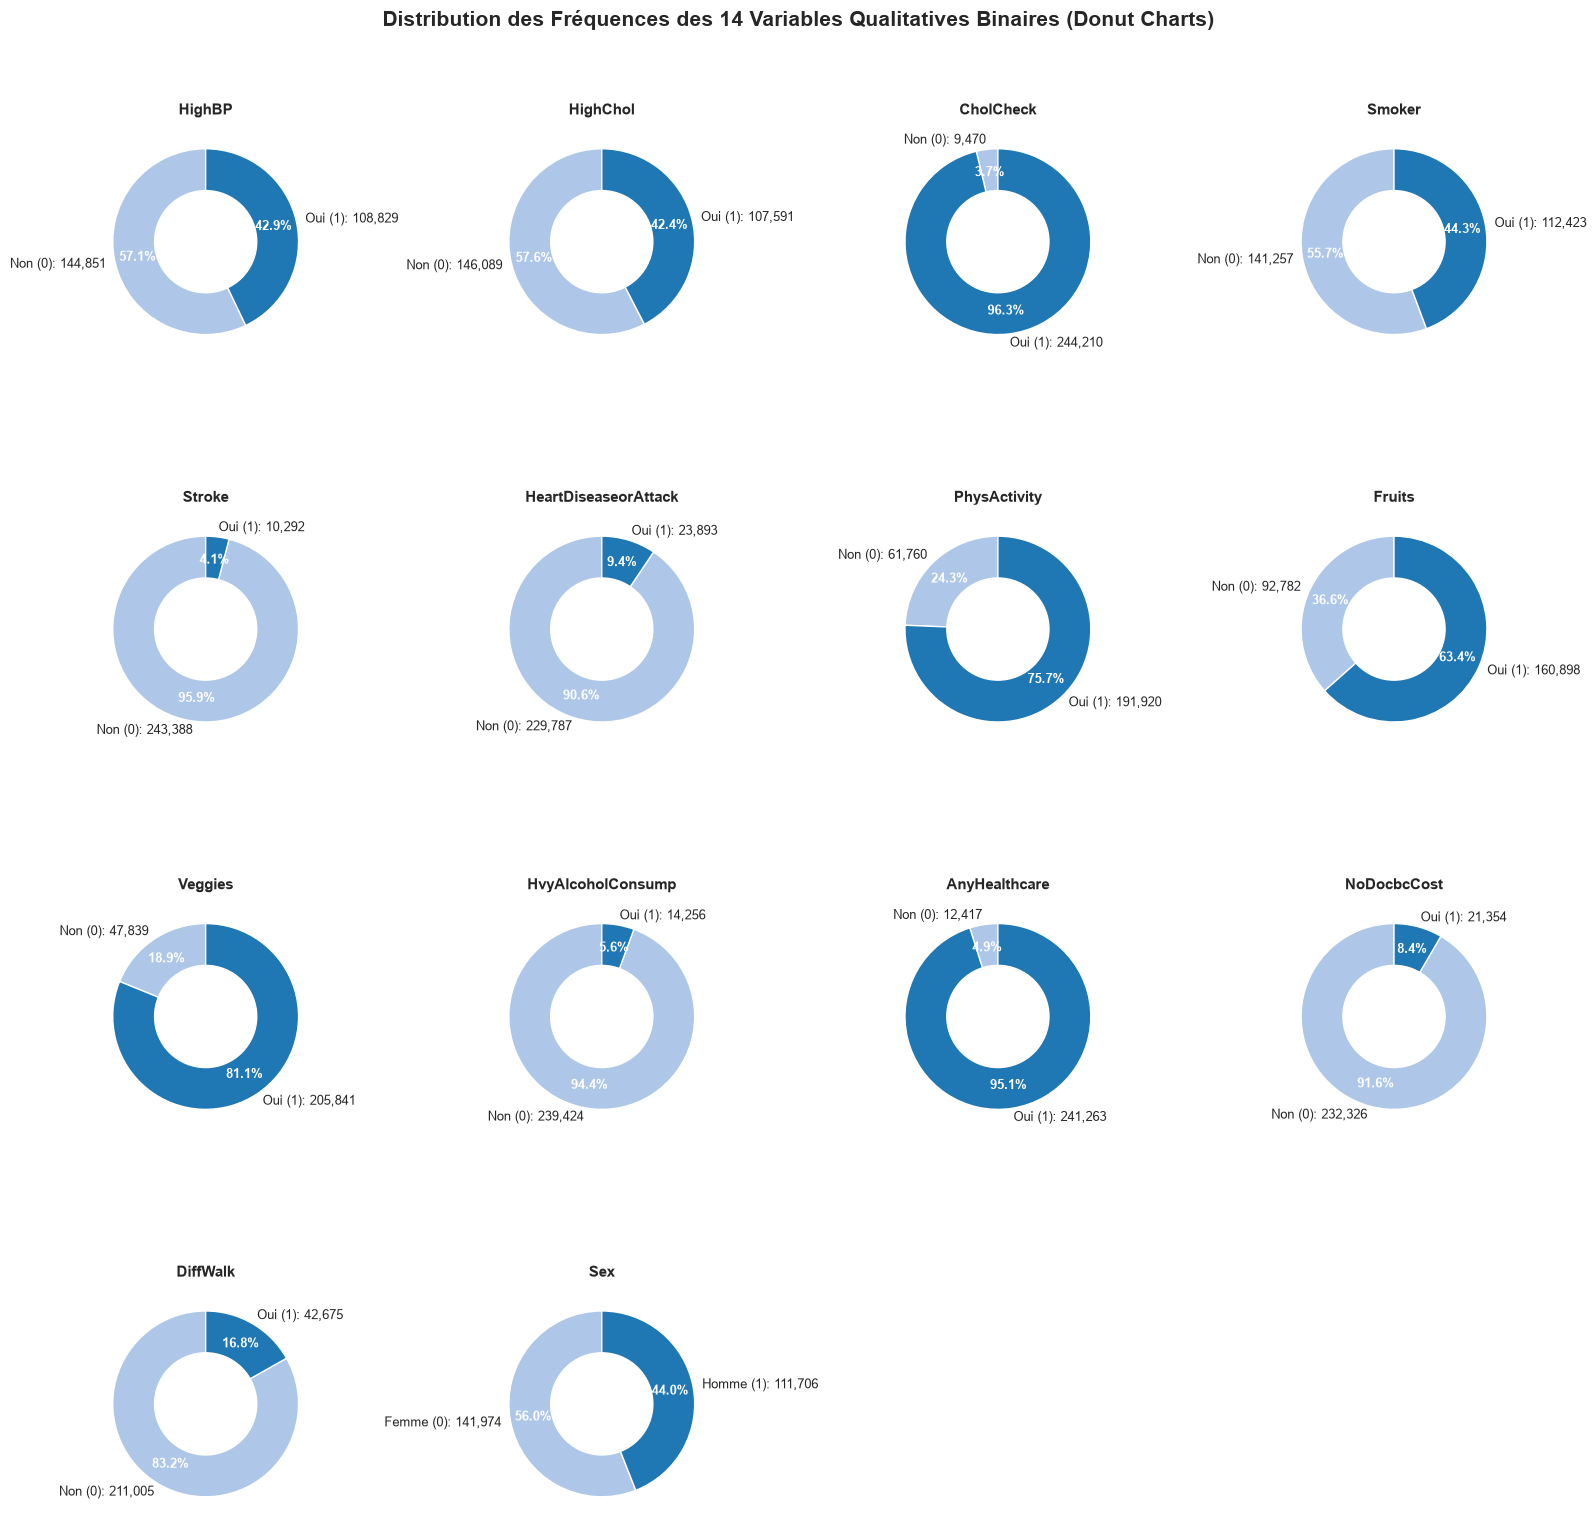

In [8]:
# 1. Visualisation des 14 variables binaires (Diagrammes circulaires / Donut charts)
fig, axes = plt.subplots(4, 4, figsize=(16, 16))
axes = axes.flatten()

colors_donut = ['#aec7e8', '#1f77b4']

for i, col in enumerate(binary_cols):
    ax = axes[i]
    counts = df[col].value_counts().sort_index()
    labels = [f"Non (0): {counts[0]:,}", f"Oui (1): {counts[1]:,}"]
    if col == 'Sex':
        labels = [f"Femme (0): {counts[0]:,}", f"Homme (1): {counts[1]:,}"]
    
    wedges, texts, autotexts = ax.pie(
        counts, 
        labels=labels, 
        autopct='%1.1f%%', 
        startangle=90, 
        colors=colors_donut,
        pctdistance=0.75,
        textprops=dict(fontsize=9)
    )
    plt.setp(autotexts, size=9, weight="bold", color="white")
    
    # Création du trou central pour effet Donut
    centre_circle = plt.Circle((0,0), 0.55, fc='white')
    ax.add_artist(centre_circle)
    ax.set_title(col, fontsize=11, fontweight='bold', pad=8)

# Masquer les sous-graphes vides restants (14 tracés sur 16 axes)
for j in range(len(binary_cols), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Distribution des Fréquences des 14 Variables Qualitatives Binaires (Donut Charts)", fontsize=15, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()


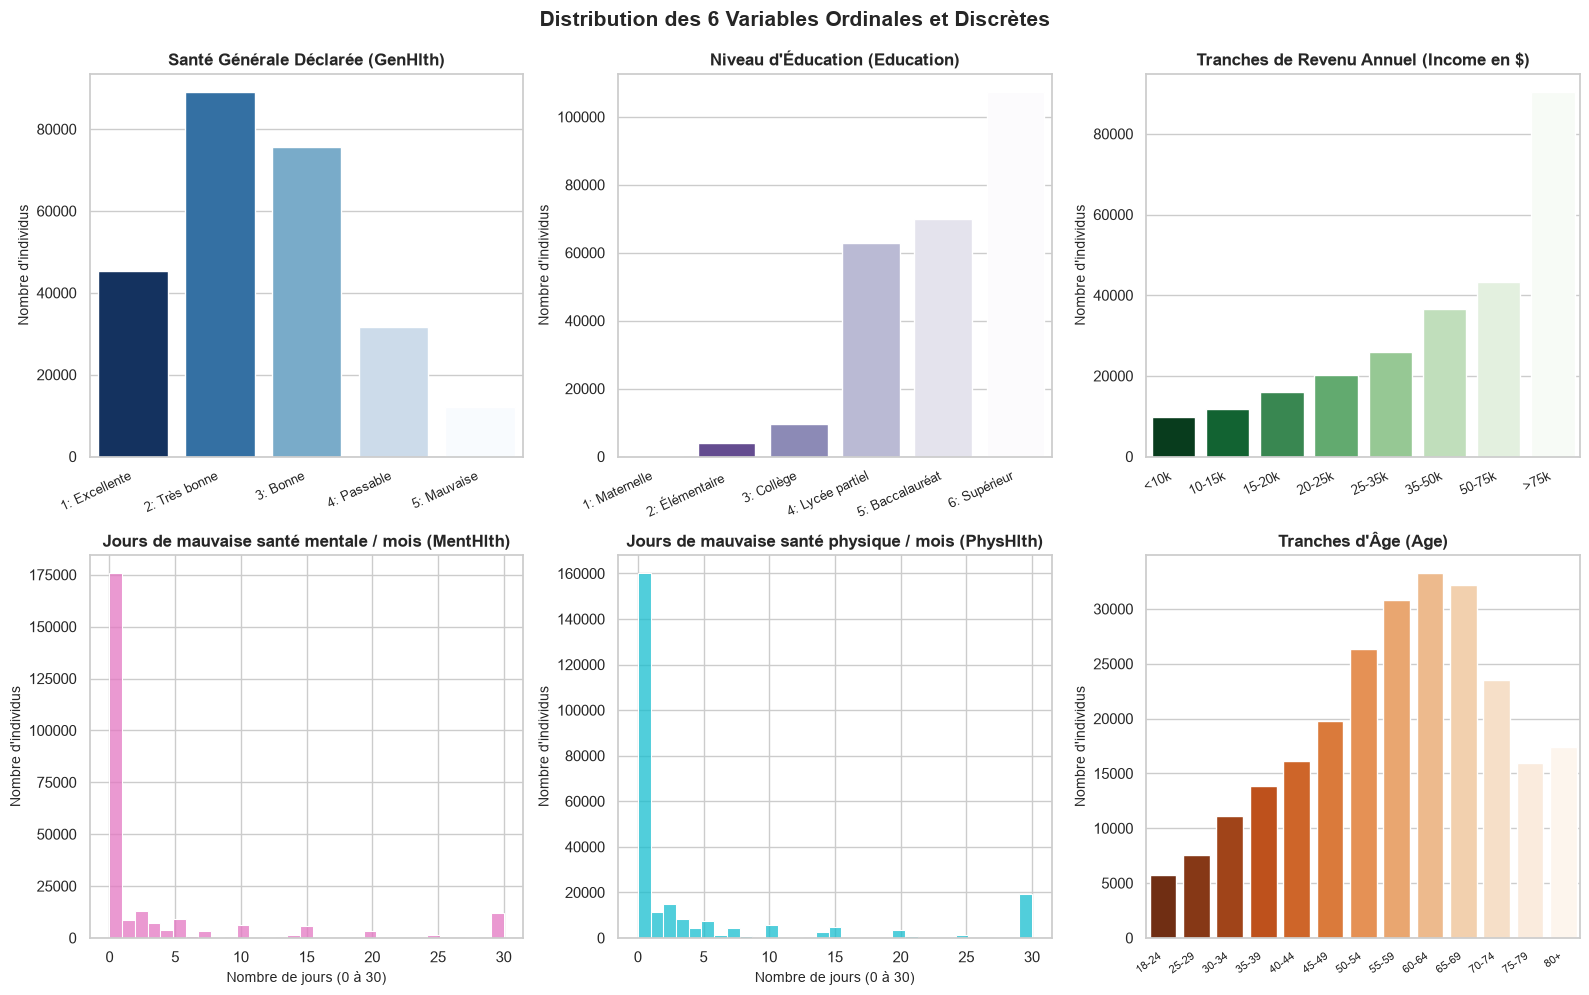

In [9]:
# 2. Visualisation des variables ordinales et discrètes
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# A. Santé Générale (GenHlth)
gen_labels = ['1: Excellente', '2: Très bonne', '3: Bonne', '4: Passable', '5: Mauvaise']
sns.countplot(x=df['GenHlth'], hue=df['GenHlth'], palette='Blues_r', legend=False, ax=axes[0, 0])
axes[0, 0].set_title("Santé Générale Déclarée (GenHlth)", fontweight='bold')
axes[0, 0].set_xticks(range(len(gen_labels)))
axes[0, 0].set_xticklabels(gen_labels, rotation=25, ha='right', fontsize=9)
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("Nombre d'individus")

# B. Niveau d'Éducation (Education)
edu_labels = ['1: Maternelle', '2: Élémentaire', '3: Collège', '4: Lycée partiel', '5: Baccalauréat', '6: Supérieur']
sns.countplot(x=df['Education'], hue=df['Education'], palette='Purples_r', legend=False, ax=axes[0, 1])
axes[0, 1].set_title("Niveau d'Éducation (Education)", fontweight='bold')
axes[0, 1].set_xticks(range(len(edu_labels)))
axes[0, 1].set_xticklabels(edu_labels, rotation=25, ha='right', fontsize=9)
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("Nombre d'individus")

# C. Tranches de Revenus (Income)
inc_labels = ['<10k', '10-15k', '15-20k', '20-25k', '25-35k', '35-50k', '50-75k', '>75k']
sns.countplot(x=df['Income'], hue=df['Income'], palette='Greens_r', legend=False, ax=axes[0, 2])
axes[0, 2].set_title("Tranches de Revenu Annuel (Income en $)", fontweight='bold')
axes[0, 2].set_xticks(range(len(inc_labels)))
axes[0, 2].set_xticklabels(inc_labels, rotation=25, ha='right', fontsize=9)
axes[0, 2].set_xlabel("")
axes[0, 2].set_ylabel("Nombre d'individus")

# D. Jours de mauvaise santé mentale (MentHlth)
sns.histplot(df['MentHlth'], bins=31, ax=axes[1, 0], color='#e377c2', edgecolor='white')
axes[1, 0].set_title("Jours de mauvaise santé mentale / mois (MentHlth)", fontweight='bold')
axes[1, 0].set_xlabel("Nombre de jours (0 à 30)")
axes[1, 0].set_ylabel("Nombre d'individus")

# E. Jours de mauvaise santé physique (PhysHlth)
sns.histplot(df['PhysHlth'], bins=31, ax=axes[1, 1], color='#17becf', edgecolor='white')
axes[1, 1].set_title("Jours de mauvaise santé physique / mois (PhysHlth)", fontweight='bold')
axes[1, 1].set_xlabel("Nombre de jours (0 à 30)")
axes[1, 1].set_ylabel("Nombre d'individus")

# F. Distribution de l'Âge
age_labels = ['18-24', '25-29', '30-34', '35-39', '40-44', '45-49', '50-54', '55-59', '60-64', '65-69', '70-74', '75-79', '80+']
sns.countplot(x=df['Age'], hue=df['Age'], palette='Oranges_r', legend=False, ax=axes[1, 2])
axes[1, 2].set_title("Tranches d'Âge (Age)", fontweight='bold')
axes[1, 2].set_xticks(range(len(age_labels)))
axes[1, 2].set_xticklabels(age_labels, rotation=35, ha='right', fontsize=8)
axes[1, 2].set_xlabel("")
axes[1, 2].set_ylabel("Nombre d'individus")

plt.suptitle("Distribution des 6 Variables Ordinales et Discrètes", fontsize=15, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()


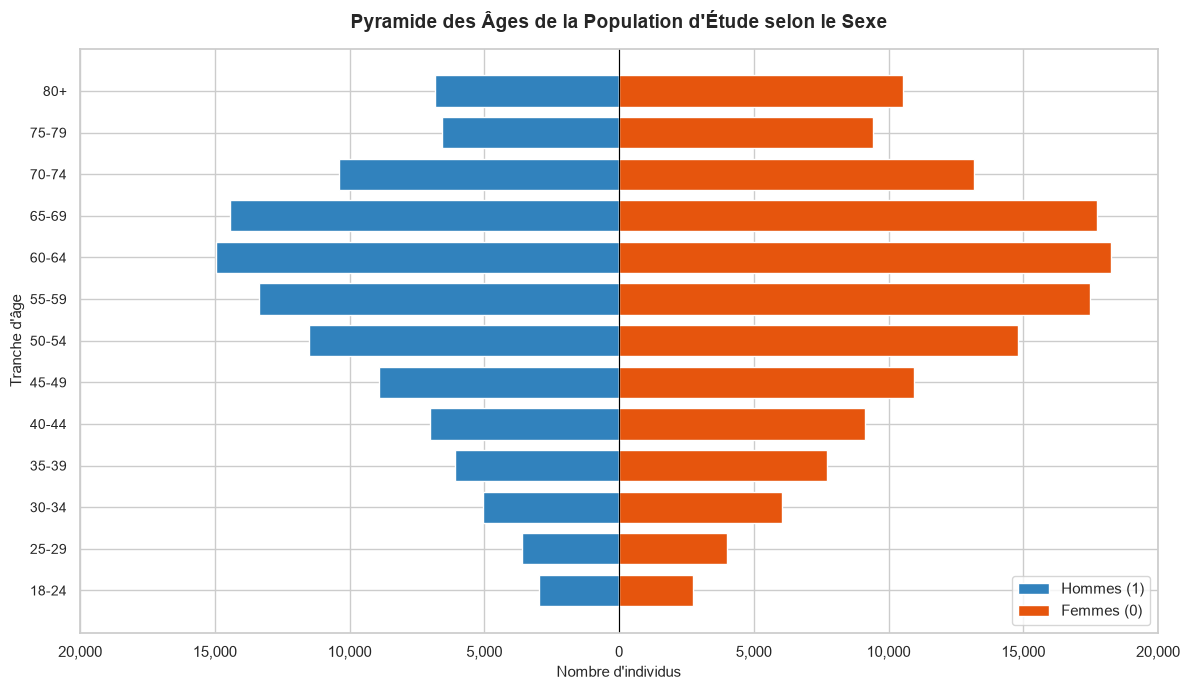

In [10]:
# Graphique spécialisé : Pyramide des Âges croisée par Sexe
age_labels = ['18-24', '25-29', '30-34', '35-39', '40-44', '45-49', '50-54', '55-59', '60-64', '65-69', '70-74', '75-79', '80+']

pyramide_df = df.groupby(['Age', 'Sex']).size().unstack(fill_value=0)
hommes = pyramide_df[1.0]
femmes = pyramide_df[0.0]

fig, ax = plt.subplots(figsize=(12, 7))

y = np.arange(len(age_labels))

# Barres pour les Hommes (gauche / valeurs négatives) et Femmes (droite)
ax.barh(y, -hommes, color='#3182bd', label='Hommes (1)', edgecolor='white', height=0.75)
ax.barh(y, femmes, color='#e6550d', label='Femmes (0)', edgecolor='white', height=0.75)

# Formatage des axes avec set_xticks d'abord pour éviter tout warning
ax.set_yticks(y)
ax.set_yticklabels(age_labels, fontsize=10)

ticks = ax.get_xticks()
ax.set_xticks(ticks)
ax.set_xticklabels([f"{abs(int(t)):,}" for t in ticks])

ax.axvline(0, color='black', linewidth=0.8)
ax.set_title("Pyramide des Âges de la Population d'Étude selon le Sexe", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Nombre d'individus", fontsize=11)
ax.set_ylabel("Tranche d'âge", fontsize=11)
ax.legend(loc='lower right', frameon=True, facecolor='white', fontsize=11)
plt.tight_layout()
plt.show()


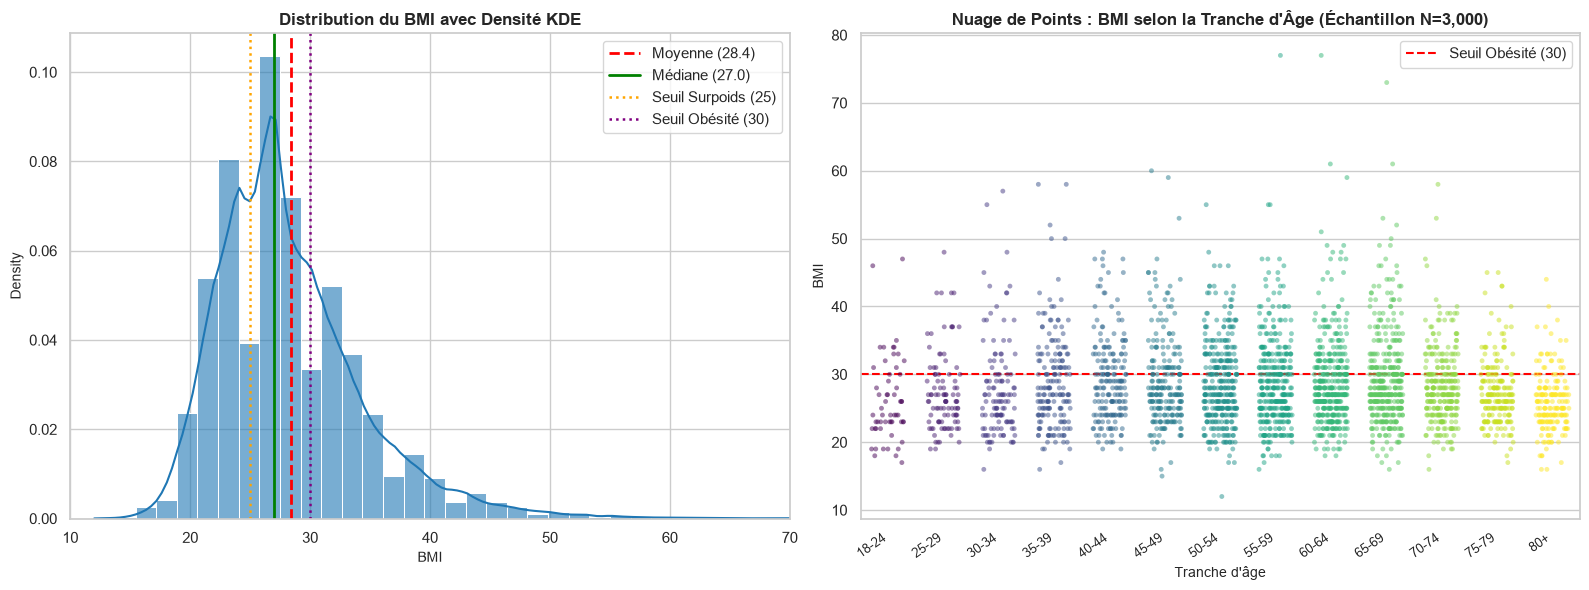

In [11]:
# Graphique pour la variable continue BMI : Histogramme KDE et Nuage de points par Âge
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# A. Histogramme + KDE + seuils OMS
sns.histplot(df['BMI'], bins=50, kde=True, color='#1f77b4', stat='density', ax=axes[0], alpha=0.6)
axes[0].axvline(df['BMI'].mean(), color='red', linestyle='--', linewidth=2, label=f"Moyenne ({df['BMI'].mean():.1f})")
axes[0].axvline(df['BMI'].median(), color='green', linestyle='-', linewidth=2, label=f"Médiane ({df['BMI'].median():.1f})")
axes[0].axvline(25.0, color='orange', linestyle=':', linewidth=1.8, label="Seuil Surpoids (25)")
axes[0].axvline(30.0, color='purple', linestyle=':', linewidth=1.8, label="Seuil Obésité (30)")
axes[0].set_title("Distribution du BMI avec Densité KDE", fontweight='bold')
axes[0].set_xlabel("BMI")
axes[0].set_xlim(10, 70)
axes[0].legend(loc='upper right', frameon=True)

# B. Nuage de points / Strip plot échantillonné pour visualiser les valeurs de BMI selon l'Âge
sample_plot = df.sample(n=3000, random_state=42)
sns.stripplot(x=sample_plot['Age'], y=sample_plot['BMI'], hue=sample_plot['Age'], jitter=0.3, size=3.5, alpha=0.5, palette='viridis', legend=False, ax=axes[1])
axes[1].set_xticks(range(len(age_labels)))
axes[1].set_xticklabels(age_labels, rotation=35, ha='right', fontsize=9)
axes[1].axhline(30.0, color='red', linestyle='--', label="Seuil Obésité (30)")
axes[1].set_title("Nuage de Points : BMI selon la Tranche d'Âge (Échantillon N=3,000)", fontweight='bold')
axes[1].set_xlabel("Tranche d'âge")
axes[1].set_ylabel("BMI")
axes[1].legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()


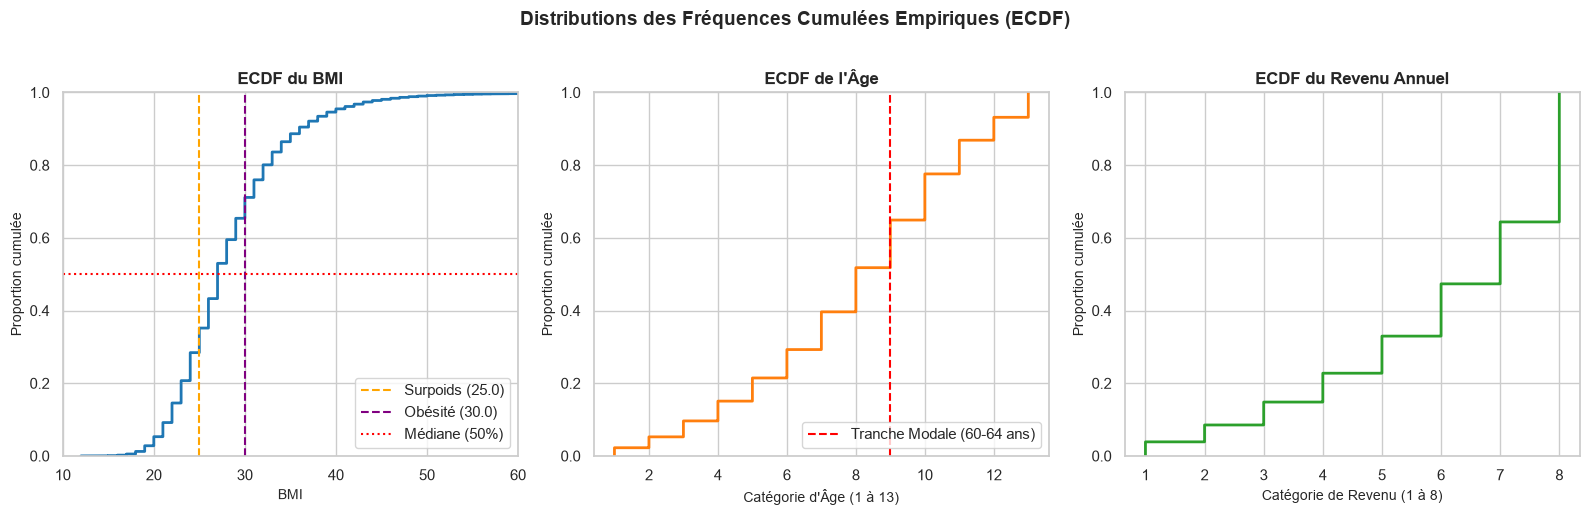

In [12]:
# 6.b Distribution des Fréquences Cumulées (ECDF)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# ECDF de BMI
sns.ecdfplot(df['BMI'], ax=axes[0], color='#1f77b4', linewidth=2)
axes[0].axvline(25.0, color='orange', linestyle='--', label="Surpoids (25.0)")
axes[0].axvline(30.0, color='purple', linestyle='--', label="Obésité (30.0)")
axes[0].axhline(0.5, color='red', linestyle=':', label="Médiane (50%)")
axes[0].set_title("ECDF du BMI", fontweight='bold')
axes[0].set_xlabel("BMI")
axes[0].set_ylabel("Proportion cumulée")
axes[0].set_xlim(10, 60)
axes[0].legend(loc='lower right', frameon=True)

# ECDF de l'Âge
sns.ecdfplot(df['Age'], ax=axes[1], color='#ff7f0e', linewidth=2)
axes[1].axvline(9.0, color='red', linestyle='--', label="Tranche Modale (60-64 ans)")
axes[1].set_title("ECDF de l'Âge", fontweight='bold')
axes[1].set_xlabel("Catégorie d'Âge (1 à 13)")
axes[1].set_ylabel("Proportion cumulée")
axes[1].legend(loc='lower right', frameon=True)

# ECDF du Revenu
sns.ecdfplot(df['Income'], ax=axes[2], color='#2ca02c', linewidth=2)
axes[2].set_title("ECDF du Revenu Annuel", fontweight='bold')
axes[2].set_xlabel("Catégorie de Revenu (1 à 8)")
axes[2].set_ylabel("Proportion cumulée")

plt.suptitle("Distributions des Fréquences Cumulées Empiriques (ECDF)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## Synthèse Finale de l'Analyse Univariée

1. **Variables Explicatives Analysées :** L'ensemble des 21 variables explicatives a été caractérisé (14 binaires, 6 ordinales, 1 continue).
2. **Qualité des Données :** Le jeu de données est complet ($0$ valeur manquante). Un pipeline d'imputation robuste par médiane (variables numériques/ordinales) et mode (variables binaires) a été conçu et validé.
3. **Traitement des Outliers :** La transformation logarithmique $\ln(\text{BMI})$ est la technique retenue car elle préserve la totalité des individus tout en résolvant l'asymétrie ($Skewness = 0.86$) et en compressant les extrêmes d'obésité sans perte d'information clinique.
4. **Normalisation :** Les échelles Min-Max $[0, 1]$ et Z-score ont été appliquées avec succès, préparant ainsi idéalement les données pour tout algorithme de machine learning supervisé.
5. **Visualisations :** Toutes les variables sont documentées graphiquement à travers des représentations appropriées (Donuts, barres catégorielles, pyramide des âges hommes/femmes, histogrammes KDE et ECDF).
